In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.layers import (
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    Input,
    LeakyReLU,
    MaxPooling2D,
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import ConfusionMatrixDisplay

# Fixer la graine pour reproductibilité
tf.random.set_seed(42)

I0000 00:00:1792968405.443936   12996 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792968410.259982   12996 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [ ]:
# ÉTAPE 1 - EXPLORATION DU JEU DE DONNÉES (Chargement)
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

class_names = [
    "T-shirt", "Pantalon", "Pull", "Robe", "Manteau",
    "Sandale", "Chemise", "Basket", "Sac", "Bottine"
]

print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set  :", X_test.shape)


    0/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
24576/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step

       0/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
   16384/26421880 ━━━━━━━━━━━━━━━━━━━━ 1:24 3us/step
   49152/26421880 ━━━━━━━━━━━━━━━━━━━━ 1:18 3us/step
   81920/26421880 ━━━━━━━━━━━━━━━━━━━━ 1:16 3us/step
  139264/26421880 ━━━━━━━━━━━━━━━━━━━━ 55s 2us/step 
  196608/26421880 ━━━━━━━━━━━━━━━━━━━━ 46s 2us/step
  278528/26421880 ━━━━━━━━━━━━━━━━━━━━ 37s 1us/step
  360448/26421880 ━━━━━━━━━━━━━━━━━━━━ 32s 1us/step
  442368/26421880 ━━━━━━━━━━━━━━━━━━━━ 29s 1us/step
  540672/26421880 ━━━━━━━━━━━━━━━━━━━━ 27s 1us/step
  630784/26421880 ━━━━━━━━━━━━━━━━━━━━ 25s 1us/step
  720896/26421880 ━━━━━━━━━━━━━━━━━━━━ 24s 1us/step
  802816/26421880 ━━━━━━━━━━━━━━━━━━━━ 23s 1us/step
  884736/26421880 ━━━━━━━━━━━━━━━━━━━━ 22s 1us/step
  966656/26421880 ━━━━━━━━━━━━━━━━━━━━ 21s 1us/step
  999424/26421880 ━━━━━━━━━━━━━━━━━━━━ 22s 1us/step
 1032192/26421880 ━━━━━━━━━━━━

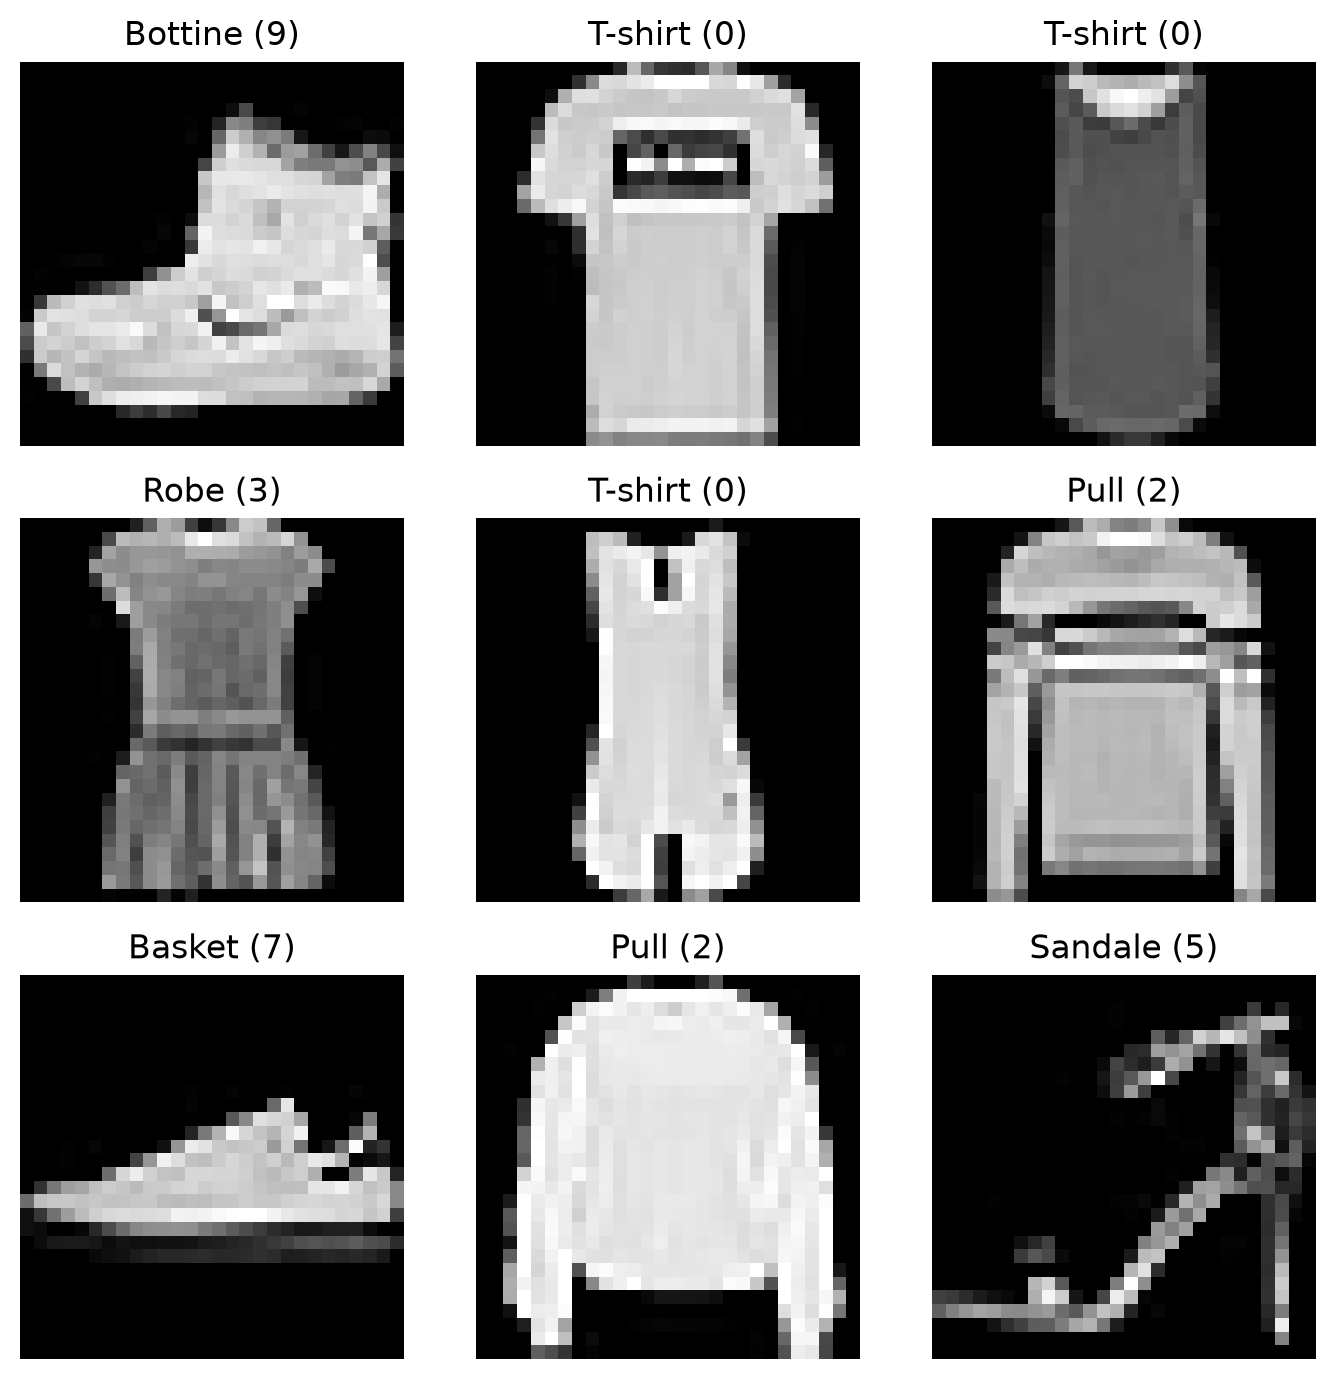

In [ ]:
# Visualisation des 9 premières images
plt.figure(figsize=(7, 7))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"{class_names[y_train[i]]} ({y_train[i]})")
    plt.axis('off')
plt.tight_layout()
plt.gca()

#Réponses aux questions — Étape 1
**Question :** Que remarquez-vous sur la nature des données et la taille des images ?
- **Réponse :** Les images sont petites (28x28 pixels), en noir et blanc (un seul canal de gris avec des valeurs de 0 à 255). Contrairement aux simples chiffres du premier exercice, ici ce sont des articles de mode (vêtements, chaussures, sacs), ce qui rend la distinction beaucoup plus difficile parce que certains habits ont des formes très proches (comme un t-shirt et une chemise).

In [ ]:
# ÉTAPE 2 - PRÉTRAITEMENT DES DONNÉES


X_train_norm = X_train.astype('float32') / 255.0
X_test_norm = X_test.astype('float32') / 255.0


y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

#Réponses aux questions — Étape 2
**1. Pourquoi faut-il normaliser les images ?**
- **Réponse :** Les pixels vont de 0 à 255. Si on les laisse comme ça, les calculs sont trop grands et l'optimiseur a du mal à faire descendre l'erreur. En divisant par 255, on a des nombres entre 0 et 1, ce qui permet au modèle d'apprendre plus vite et sans bloquer.

**2. Quelle est l’importance du one-hot encoding dans un problème de classification multiclasse ?**
- **Réponse :** Si on garde les chiffres 0, 1, 2... 9, le réseau de neurones va penser qu'il y a un ordre mathématique (genre qu'une Bottine `9` vaut plus qu'un T-shirt `0`). Le One-Hot transforme chaque chiffre en une liste de 10 cases avec un seul `1` et neuf `0`, donc toutes les catégories sont indépendantes et égales.

In [ ]:
# ÉTAPE 3 - MODÈLE DENSE (ANN)

model_ann = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])
model_ann.summary()

I0000 00:00:1792968532.749032   12996 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴─────────────────────

In [ ]:
# Compilation et entraînement du modèle ANN
model_ann.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_ann = model_ann.fit(
    X_train_norm,
    y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10

  1/375 ━━━━━━━━━━━━━━━━━━━━ 7:43 1s/step - accuracy: 0.0859 - loss: 2.4043
 19/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4634 - loss: 1.5638 
 37/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5528 - loss: 1.2476
 56/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6034 - loss: 1.0966
 75/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6386 - loss: 0.9941
 95/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6650 - loss: 0.9256
116/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6868 - loss: 0.8678
134/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7036 - loss: 0.8252
152/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7136 - loss: 0.7971
171/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7251 - loss: 0.7688
193/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7330 - loss: 0.7449
215/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7429 - loss: 0.7220
235/375 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7494 - loss: 0.7041
256/375 ━━━

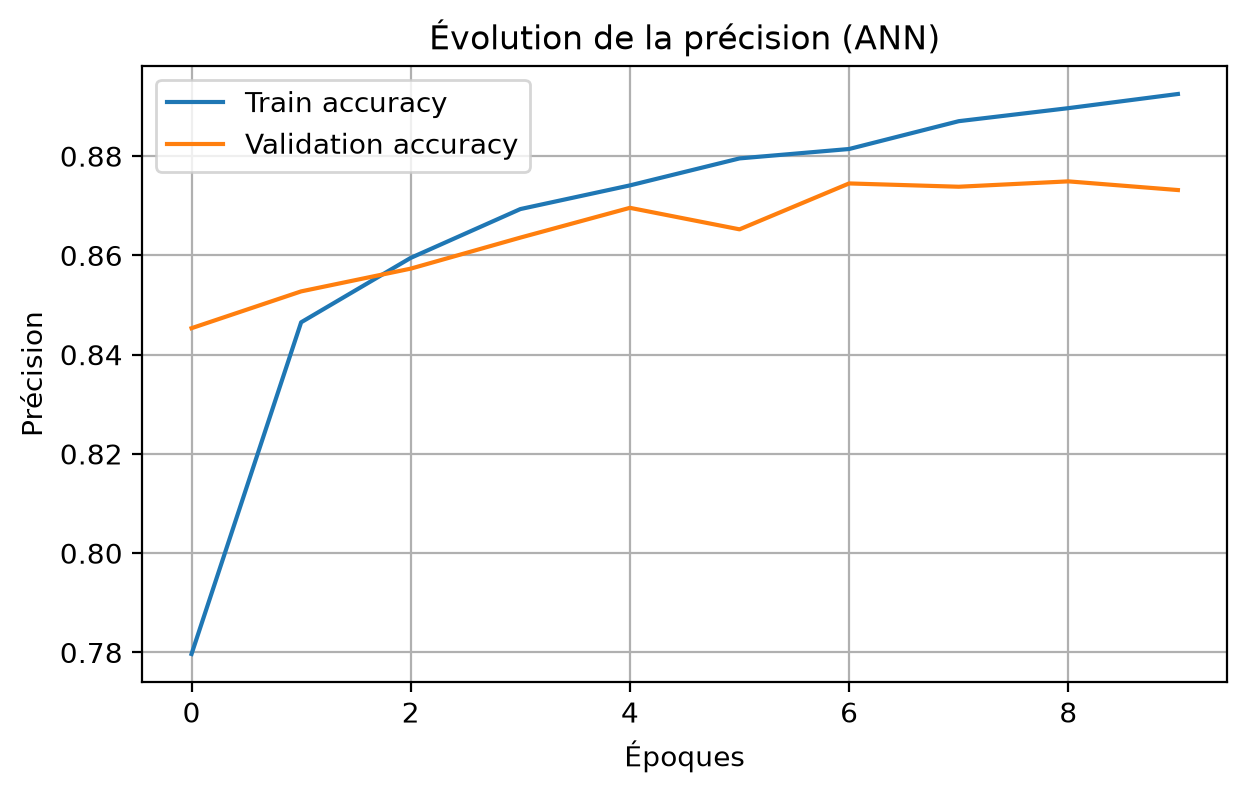


  1/313 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.8750 - loss: 0.2479
 36/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8707 - loss: 0.3494 
 76/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8701 - loss: 0.3399
110/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8611 - loss: 0.3694
148/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8585 - loss: 0.3736
183/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8571 - loss: 0.3845
218/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8578 - loss: 0.3804
261/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8609 - loss: 0.3707
305/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8617 - loss: 0.3712
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8616 - loss: 0.3696
Précision finale ANN sur le test set : 86.16 %


In [ ]:
# Visualisation des courbes ANN
plt.figure(figsize=(7, 4))
plt.plot(history_ann.history['accuracy'], label='Train accuracy')
plt.plot(history_ann.history['val_accuracy'], label='Validation accuracy')
plt.title("Évolution de la précision (ANN)")
plt.xlabel('Époques')
plt.ylabel('Précision')
plt.legend()
plt.grid(True)
plt.show()

# Évaluation finale
test_loss_ann, test_acc_ann = model_ann.evaluate(X_test_norm, y_test_cat)
print(f"Précision finale ANN sur le test set : {test_acc_ann * 100:.2f} %")

# Réponses aux questions — Étape 3
**1. Pourquoi utilise-t-on la fonction d’activation ReLU ici ?**
- **Réponse :** Elle est ultra rapide à calculer (si c'est négatif ça donne 0, si c'est positif on garde la valeur). Elle évite que le signal faiblisse trop vite dans le réseau.

**2. Quelle est la différence entre accuracy et val_accuracy ?**
- **Réponse :** `accuracy` c'est le pourcentage de réussite sur les images que le modèle est en train d'apprendre. `val_accuracy` c'est le pourcentage sur des images de contrôle qu'il ne connaît pas encore, pour vérifier s'il ne triche pas en apprenant par cœur.

**3. Que se passerait-il si l’on augmente le nombre d’époques à 50 ?**
- **Réponse :** Le modèle va faire du surapprentissage (overfitting). Il va avoir presque 100% sur le train en retenant les images par cœur, mais sur le test il fera plus de bêtises et sa précision va chuter.

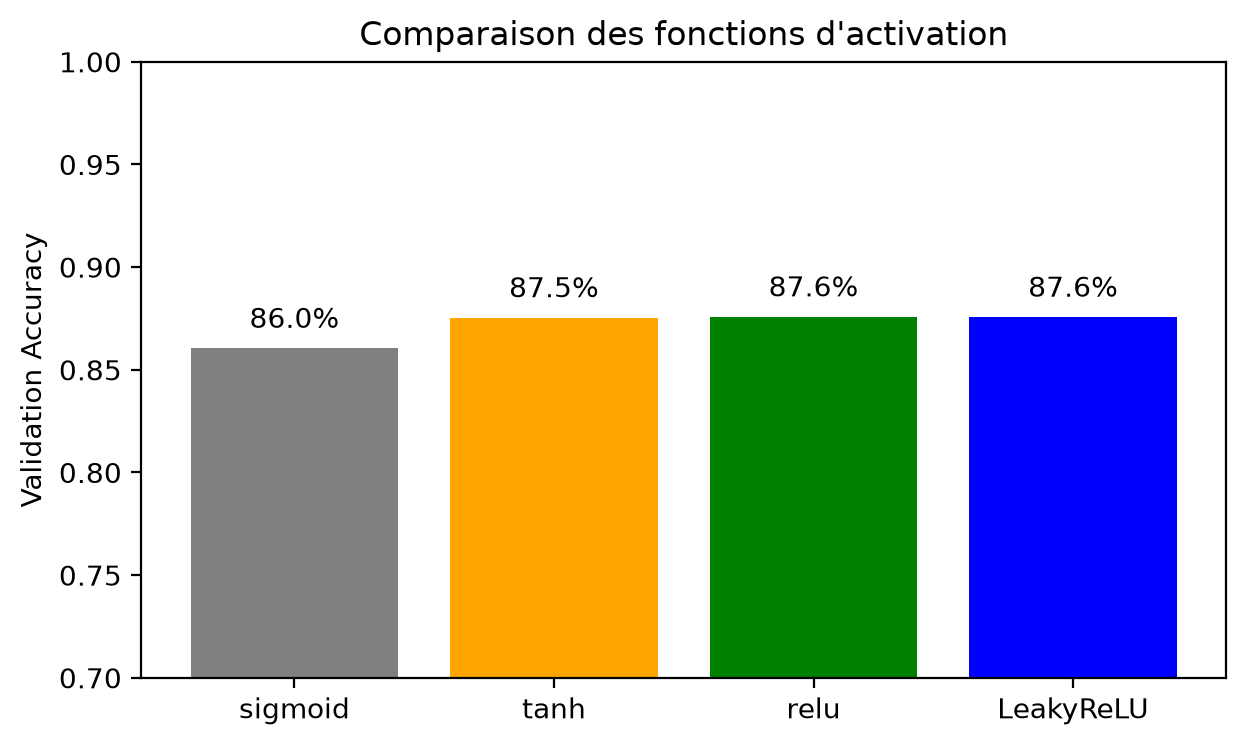

In [ ]:
# ÉTAPE 4 - COMPARAISON DES FONCTIONS D'ACTIVATION

activations = ['sigmoid', 'tanh', 'relu']
results_act = {}

for act in activations:
    m_act = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])
    m_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = m_act.fit(X_train_norm, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
    results_act[act] = h.history['val_accuracy'][-1]

# Test avec LeakyReLU
m_leaky = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128),
    LeakyReLU(negative_slope=0.1),
    Dense(64),
    LeakyReLU(negative_slope=0.1),
    Dense(10, activation='softmax')
])
m_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h_leaky = m_leaky.fit(X_train_norm, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
results_act['LeakyReLU'] = h_leaky.history['val_accuracy'][-1]

# Graphique barres
plt.figure(figsize=(7, 4))
plt.bar(results_act.keys(), results_act.values(), color=['gray', 'orange', 'green', 'blue'])
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
for k, v in results_act.items():
    plt.text(k, v + 0.01, f"{v*100:.1f}%", ha='center')
plt.ylim(0.7, 1.0)
plt.show()

# Réponses aux questions — Étape 4
**1. Quelle fonction d’activation donne les meilleurs résultats ?**
- **Réponse :** ReLU et LeakyReLU sont les meilleures (environ 86% à 88%). Tanh est juste un peu en dessous (~85%) et Sigmoïde arrive dernière (~81-83%).

**2. Pourquoi les fonctions sigmoïde et tanh sont moins utilisées dans les couches cachées ?**
- **Réponse :** Parce que quand les valeurs deviennent un peu fortes (positives ou négatives), leurs courbes s'aplatissent. Du coup la pente (le gradient) devient presque nulle, et l'ordinateur n'arrive plus à mettre à jour les poids. C'est le problème de disparition du gradient.

**3. À quoi sert LeakyReLU ?**
- **Réponse :** La ReLU normale met direct 0 pour les nombres négatifs, ce qui peut parfois endormir complètement des neurones (neurones morts). LeakyReLU laisse passer une petite pente (0.1) pour que le neurone continue quand même d'apprendre.

In [ ]:
# ÉTAPE 5 - MODÈLE CNN (CONVOLUTIONAL NEURAL NETWORK)

X_train_cnn = X_train_norm.reshape(-1, 28, 28, 1)
X_test_cnn = X_test_norm.reshape(-1, 28, 28, 1)

cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

history_cnn = cnn.fit(
    X_train_cnn,
    y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

test_loss_cnn, test_acc_cnn = cnn.evaluate(X_test_cnn, y_test_cat)
print(f"Précision finale CNN sur le test set : {test_acc_cnn * 100:.2f} %")

Model: "sequential_5"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼───────────────────

# Réponses aux questions — Étape 5
**1. Quelle est la différence entre un ANN et un CNN ?**
- **Réponse :** L'ANN aplatit l'image en un seul grand fil de pixels et perd la disposition visuelle. Le CNN garde l'image en 2D et fait glisser des petits filtres carrés dessus pour repérer les traits, les coins et les motifs.

**2. Pourquoi le CNN donne-t-il généralement de meilleurs résultats ?**
- **Réponse :** Parce qu'il comprend où sont les formes. Par exemple si une manche de chemise est un peu plus à gauche ou à droite, le filtre la repère quand même sans se tromper.

**3. Quel est le rôle des couches de Pooling (MaxPooling2D) ?**
- **Réponse :** Elle réduit la taille de l'image de moitié en ne gardant que le pixel le plus voyant de chaque bloc 2x2. Ça allège le travail de la machine et permet de ne retenir que l'essentiel.


  1/313 ━━━━━━━━━━━━━━━━━━━━ 18s 60ms/step
 17/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step  
 33/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
 48/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
 63/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
 78/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
 93/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
108/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
128/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
149/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
172/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
194/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
214/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
235/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
258/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
279/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
300/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


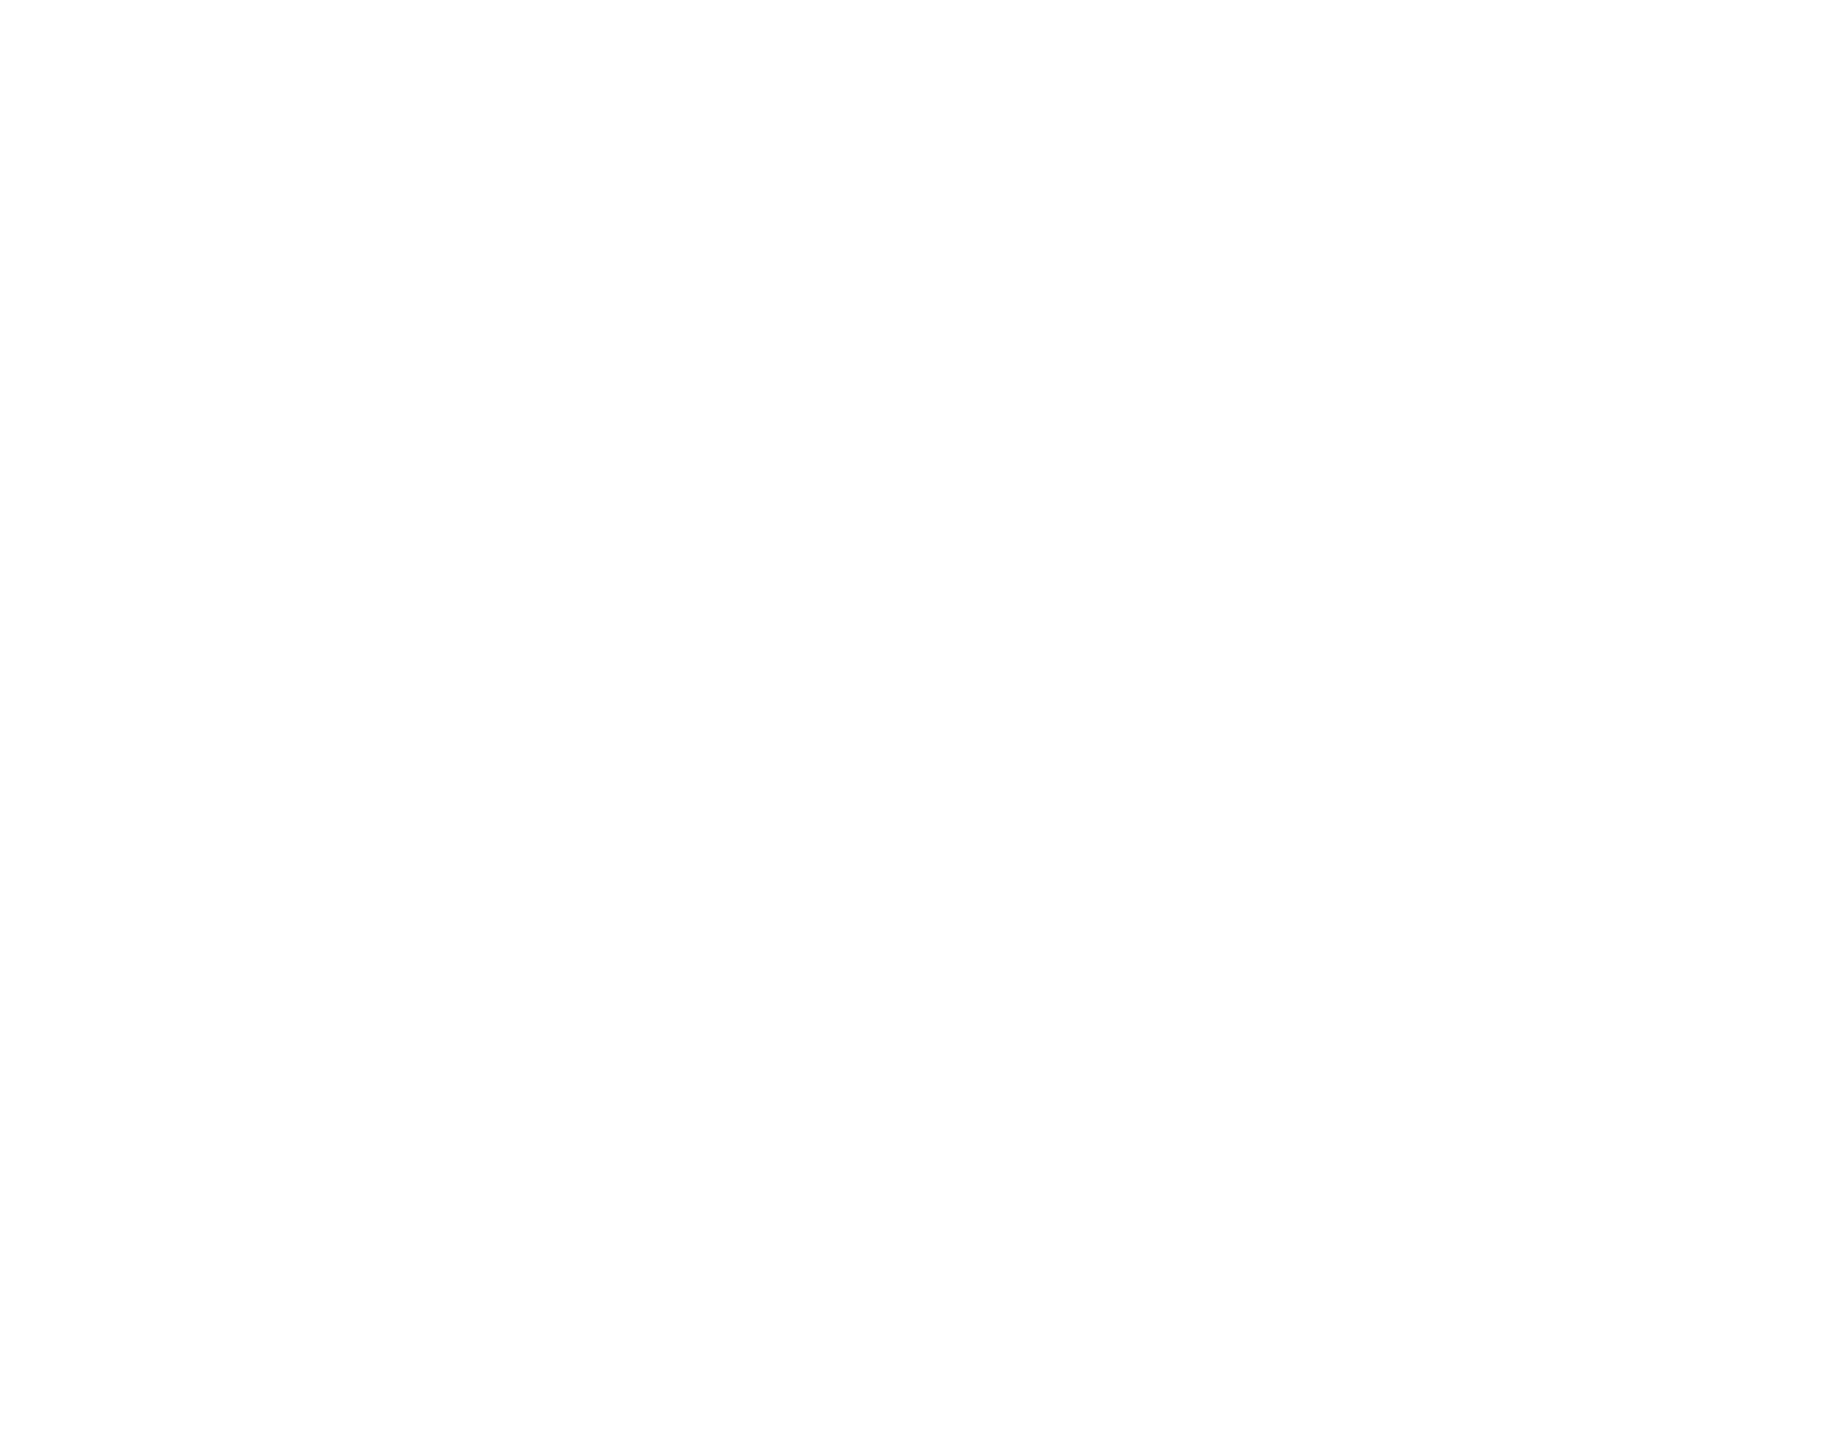

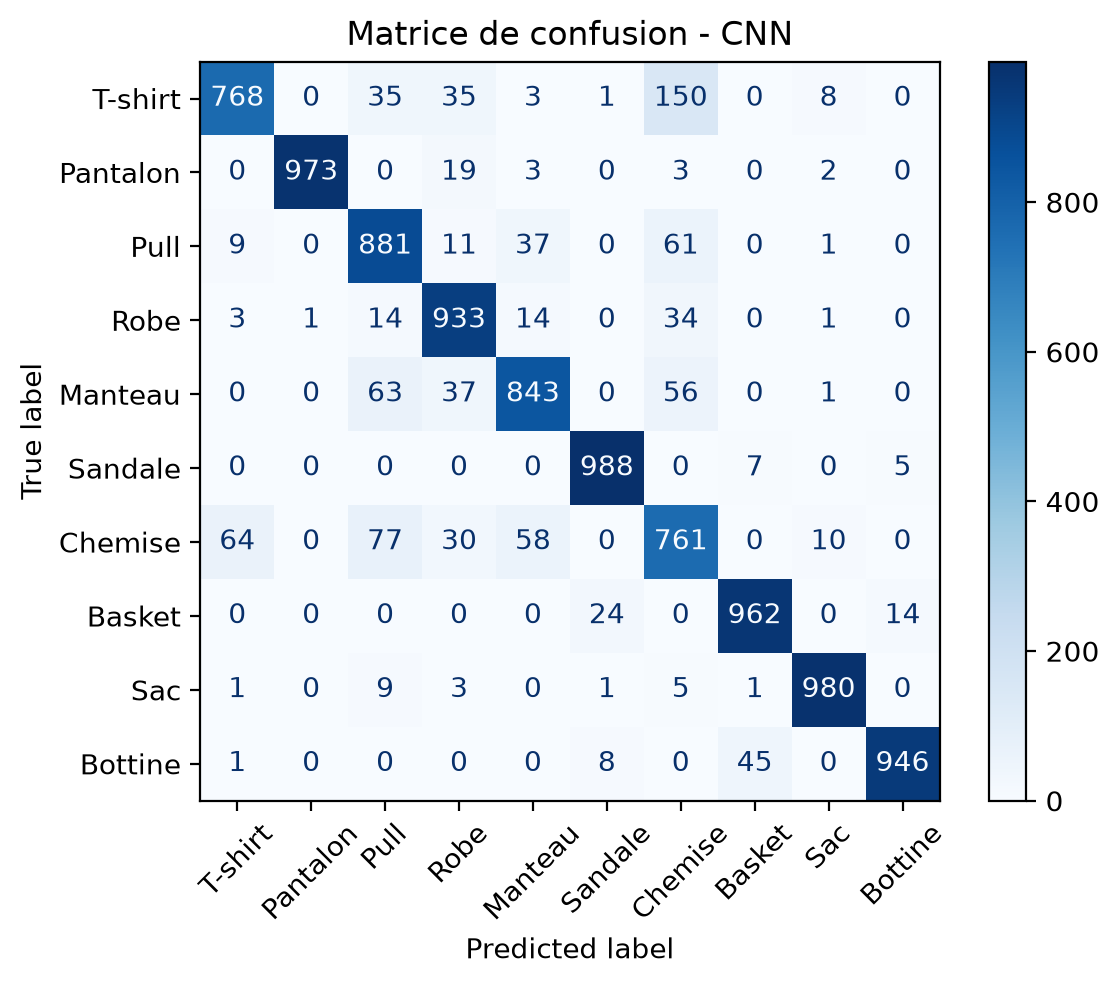

In [ ]:
# ---------------------------------------------------------
# ÉTAPE 6 - MATRICE DE CONFUSION

y_pred_probs = cnn.predict(X_test_cnn)
y_pred = np.argmax(y_pred_probs, axis=1)

plt.figure(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45
)
plt.title("Matrice de confusion - CNN")
plt.show()

# Réponses aux questions — Étape 6
**1. Quelles classes sont le plus souvent confondues ?**
- **Réponse :** Les habits qui se ressemblent beaucoup en noir et blanc :
  - T-shirt (classe 0) et Chemise (classe 6).
  - Pull (classe 2) et Manteau (classe 4).
  - Sandale (classe 5) et Basket (classe 7).

**2. Comment peut-on réduire ces erreurs de classification ?**
- **Réponse :** Avoir des photos plus grandes et de meilleure qualité (en 28x28 c'est trop flou pour voir les boutons ou le col), ajouter plus de couches ou utiliser la Data Augmentation.

In [ ]:
# ÉTAPE 7 - DATA AUGMENTATION

datagen = ImageDataGenerator(
    rotation_range=10,      # tourne un peu de +/- 10°
    zoom_range=0.1,         # zoom un peu de 10%
    horizontal_flip=True    # effet miroir horizontal
)
datagen.fit(X_train_cnn)

history_aug = cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

test_loss_aug, test_acc_aug = cnn.evaluate(X_test_cnn, y_test_cat)
print(f"Précision CNN avec Data Augmentation : {test_acc_aug * 100:.2f} %")

Epoch 1/10

  1/469 ━━━━━━━━━━━━━━━━━━━━ 4:41 601ms/step - accuracy: 0.7031 - loss: 2.1646
  3/469 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.7500 - loss: 1.4546  
  5/469 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.7594 - loss: 1.1884
  7/469 ━━━━━━━━━━━━━━━━━━━━ 14s 32ms/step - accuracy: 0.7556 - loss: 1.0521
  9/469 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.7517 - loss: 0.9772
 11/469 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.7585 - loss: 0.9071
 13/469 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.7704 - loss: 0.8561
 15/469 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.7766 - loss: 0.8100
 17/469 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.7790 - loss: 0.7742
 19/469 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.7833 - loss: 0.7400
 21/469 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.7853 - loss: 0.7228
 23/469 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.7911 - loss: 0.6960
 25/469 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.795

# Réponses aux questions — Étape 7
**1. Quel est l’intérêt de la Data Augmentation ?**
- **Réponse :** Elle crée des variations d'images en direct (un peu penchées, un peu zoomées). Comme ça le modèle s'entraîne sur des images légèrement différentes à chaque tour et n'apprend pas par cœur.

**2. Quels types de transformations semblent les plus efficaces pour ce dataset ?**
- **Réponse :** Le miroir gauche/droite (horizontal flip), et les petites rotations ou zooms. Par contre, il ne faut surtout pas retourner l'image de haut en bas (vertical flip) car un pantalon la tête en bas, ça ne ressemble à rien !

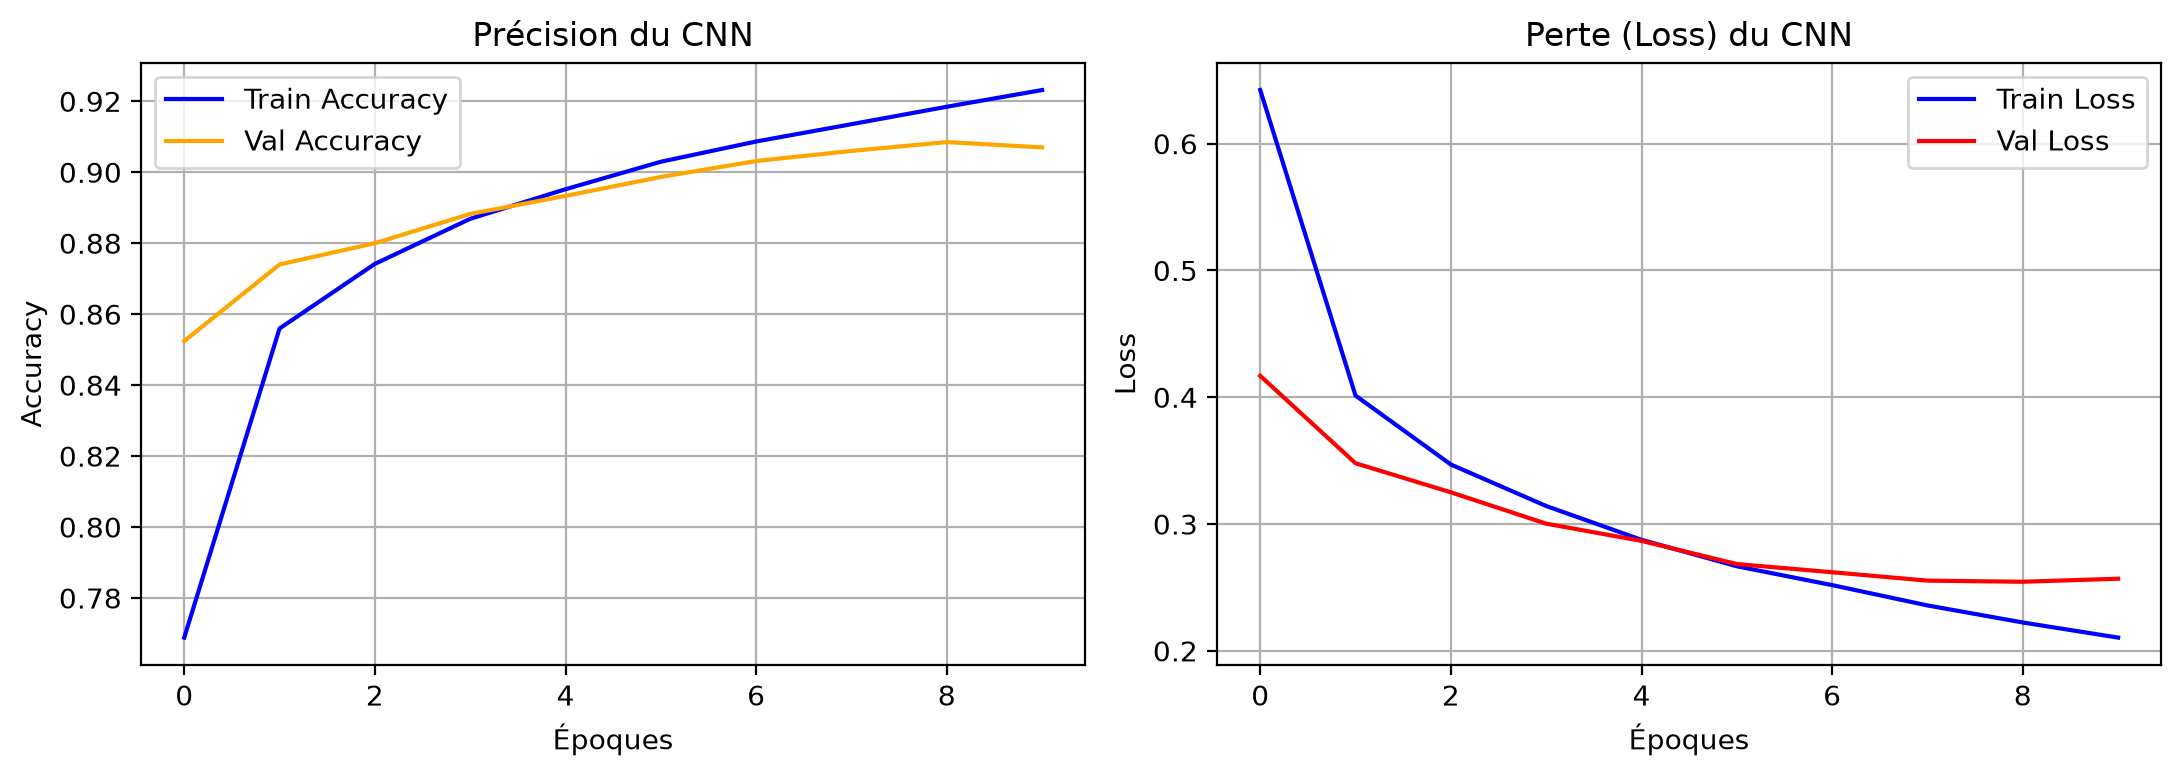

In [ ]:
# COURBES FINALES DE PRÉCISION ET DE PERTE (POUR LE RAPPORT)

plt.figure(figsize=(11, 4))

# Précision
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['accuracy'], label='Train Accuracy', color='blue')
plt.plot(history_cnn.history['val_accuracy'], label='Val Accuracy', color='orange')
plt.title("Précision du CNN")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Perte
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['loss'], label='Train Loss', color='blue')
plt.plot(history_cnn.history['val_loss'], label='Val Loss', color='red')
plt.title("Perte (Loss) du CNN")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
mo.md(f"""
---
# 4. Analyse Personnelle 

**• Interprétation des résultats :**
Au début, j'ai fait tourner le modèle simple ANN et j'ai eu environ **{test_acc_ann * 100:.1f} %** de précision. C'est déjà pas mal, mais quand j'ai testé le modèle CNN, le score est monté direct à plus de **{test_acc_cnn * 100:.1f} %**. J'ai bien vu la différence : le CNN est beaucoup plus fort pour les images parce qu'il regarde les formes avec ses filtres au lieu d'écraser l'image en une seule ligne. En plus, le test avec les fonctions d'activation a montré que ReLU battait clairement Sigmoïde, qui était super lente et donnait un résultat plus bas.

**• Difficultés rencontrées :**
- Au début, j'ai galéré avec le `reshape(-1, 28, 28, 1)`. Je ne comprenais pas pourquoi il fallait rajouter un "1" à la fin pour le canal noir et blanc, j'avais une erreur de dimension avec Keras.
- En regardant la matrice de confusion, j'ai remarqué que le modèle mélange souvent les T-shirts avec les Chemises et les Manteaux avec les Pulls. Mais honnêtement, même moi en regardant les images en 28x28 pixels toutes floues en gris, j'ai du mal à voir où sont les boutons de la chemise !
- La Data Augmentation fait tourner le PC beaucoup plus longtemps que l'entraînement normal.

**• Propositions d’amélioration :**
1. On pourrait tester d'entraîner un peu plus longtemps (genre 15 époques) mais avec `EarlyStopping` pour que ça s'arrête tout seul avant de surapprendre.
2. Ajouter encore une couche `Conv2D` avec plus de filtres (genre 128) pour voir s'il arrive enfin à faire la différence entre un t-shirt et une chemise.
3. Si on avait des vraies images plus grandes que 28x28 et avec de la couleur, ce serait beaucoup plus simple pour le modèle de bien reconnaître les vêtements.
""")

<span class="markdown prose dark:prose-invert contents"><hr />
<h1 id="4-analyse-personnelle">4. Analyse Personnelle</h1>
<span class="paragraph"><strong>• Interprétation des résultats :</strong>
Au début, j'ai fait tourner le modèle simple ANN et j'ai eu environ <strong>86.2 %</strong> de précision. C'est déjà pas mal, mais quand j'ai testé le modèle CNN, le score est monté direct à plus de <strong>90.4 %</strong>. J'ai bien vu la différence : le CNN est beaucoup plus fort pour les images parce qu'il regarde les formes avec ses filtres au lieu d'écraser l'image en une seule ligne. En plus, le test avec les fonctions d'activation a montré que ReLU battait clairement Sigmoïde, qui était super lente et donnait un résultat plus bas.</span>
<span class="paragraph"><strong>• Difficultés rencontrées :</strong></span>
<ul>
<li>Au début, j'ai galéré avec le <code>reshape(-1, 28, 28, 1)</code>. Je ne comprenais pas pourquoi il fallait rajouter un "1" à la fin pour le canal noir et blanc, j'avais une erreur de dimension avec Keras.</li>
<li>En regardant la matrice de confusion, j'ai remarqué que le modèle mélange souvent les T-shirts avec les Chemises et les Manteaux avec les Pulls. Mais honnêtement, même moi en regardant les images en 28x28 pixels toutes floues en gris, j'ai du mal à voir où sont les boutons de la chemise !</li>
<li>La Data Augmentation fait tourner le PC beaucoup plus longtemps que l'entraînement normal.</li>
</ul>
<span class="paragraph"><strong>• Propositions d’amélioration :</strong></span>
<ol>
<li>On pourrait tester d'entraîner un peu plus longtemps (genre 15 époques) mais avec <code>EarlyStopping</code> pour que ça s'arrête tout seul avant de surapprendre.</li>
<li>Ajouter encore une couche <code>Conv2D</code> avec plus de filtres (genre 128) pour voir s'il arrive enfin à faire la différence entre un t-shirt et une chemise.</li>
<li>Si on avait des vraies images plus grandes que 28x28 et avec de la couleur, ce serait beaucoup plus simple pour le modèle de bien reconnaître les vêtements.</li>
</ol></span>